<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/Hysteresis_Loop_Ni_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

In [ ]:
!uv pip install mumaxplus matplotlib numpy

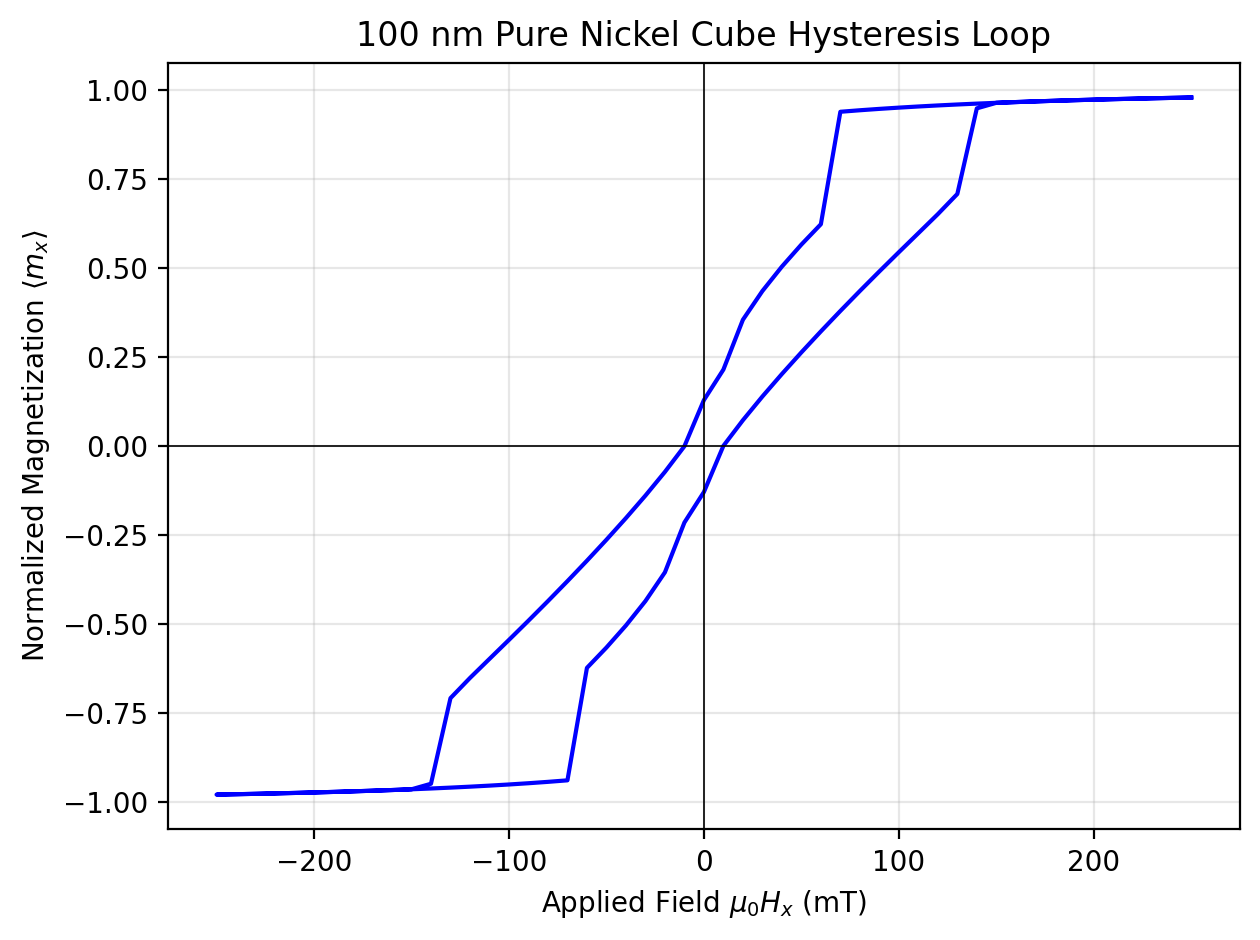

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from mumaxplus import World, Grid, Ferromagnet

plt.rcParams["figure.dpi"] = 200

cell = 100e-9 / 32
world = World(cellsize=(cell, cell, cell))
grid = Grid((32, 32, 32))

magnet = Ferromagnet(world, grid)
magnet.msat = 490e3
magnet.aex = 9e-12
magnet.kc1 = -4.5e3
magnet.anisC1 = (1, 0, 0)
magnet.anisC2 = (0, 1, 0)
magnet.magnetization = (1.0, 0.05, 0.01)

fields = np.concatenate([
    np.linspace(0.25, -0.25, 51),
    np.linspace(-0.25, 0.25, 51)[1:]
])

b_mT = []
mx = []

for b in fields:
    world.bias_magnetic_field = (float(b), 0.0, 0.0)
    magnet.minimize()
    b_mT.append(b * 1e3)
    mx.append(magnet.magnetization.average()[0])

plt.plot(b_mT, mx, color='blue', linewidth=1.5)
plt.xlabel("Applied Field $\\mu_0 H_x$ (mT)")
plt.ylabel("Normalized Magnetization $\\langle m_x \\rangle$")
plt.title("100 nm Pure Nickel Cube Hysteresis Loop")
plt.axhline(0, color="black", linewidth=0.6)
plt.axvline(0, color="black", linewidth=0.6)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()